Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 19s 36ms/step - accuracy: 0.9360 - loss: 0.2223
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 17s 28ms/step - accuracy: 0.9799 - loss: 0.0681
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 21s 28ms/step - accuracy: 0.9869 - loss: 0.0441
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 21s 29ms/step - accuracy: 0.9900 - loss: 0.0335
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - accuracy: 0.9922 - loss: 0.0250

 MODEL 1 - CNN RESULTS
Test Accuracy: 98.59 %
Test Loss: 0.0407


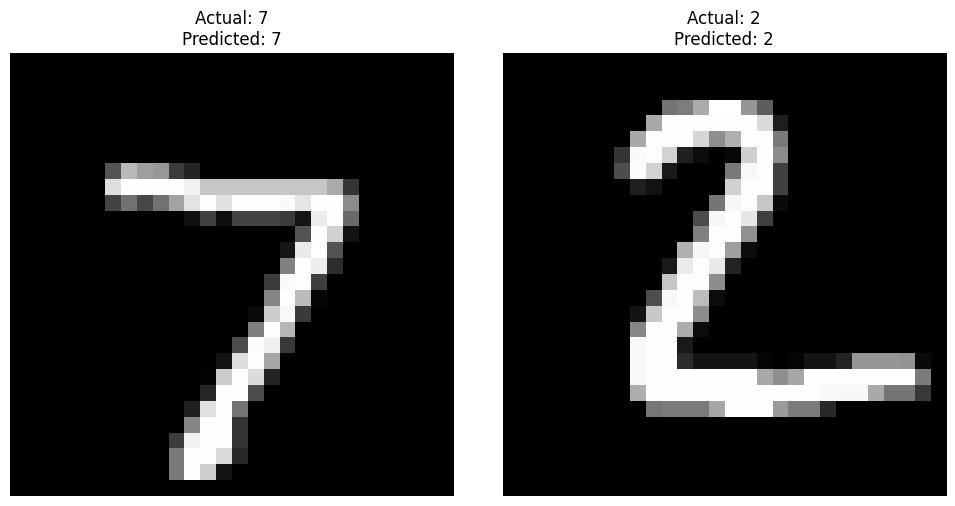

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 71s 144ms/step - accuracy: 0.9436 - loss: 0.1866
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 83s 146ms/step - accuracy: 0.9856 - loss: 0.0466
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 67s 143ms/step - accuracy: 0.9900 - loss: 0.0317
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 81s 142ms/step - accuracy: 0.9929 - loss: 0.0231
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 81s 141ms/step - accuracy: 0.9939 - loss: 0.0193

 MODEL 2 - DEEPER CNN RESULTS
Test Accuracy: 99.1 %
Test Loss: 0.0288


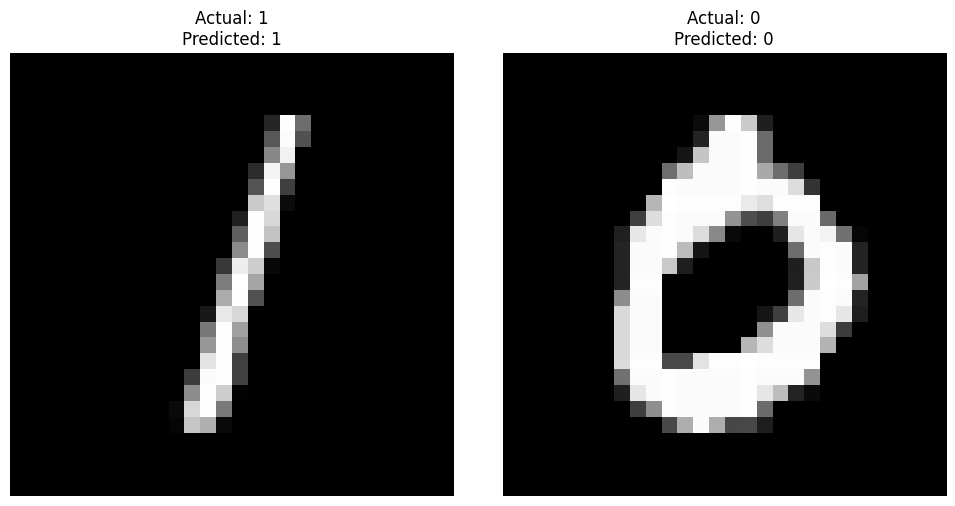

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.utils import to_categorical

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Normalize images
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Reshape images
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

# One-hot encoding
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)


# Function to train and display results
def train_model(model, name, indices):

    model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

    model.fit(x_train, y_train, epochs=5,
              batch_size=128, verbose=1)

    loss, acc = model.evaluate(x_test, y_test, verbose=0)

    print("\n", name, "RESULTS")
    print("Test Accuracy:", round(acc * 100, 2), "%")
    print("Test Loss:", round(loss, 4))

    # Predict two images
    pred = model.predict(x_test[indices], verbose=0)

    plt.figure(figsize=(10, 5))

    for i, idx in enumerate(indices):
        predicted = np.argmax(pred[i])
        actual = np.argmax(y_test[idx])
        vector = y_test[idx].astype(int).tolist()

        plt.subplot(1, 2, i + 1)
        plt.imshow(x_test[idx].reshape(28, 28), cmap='gray')
        plt.title(f'Actual: {actual}\nPredicted: {predicted}')
        plt.xlabel(f'One-hot: {vector}', fontsize=8)
        plt.axis('off')

    plt.tight_layout()
    plt.show()


# MODEL 1: Basic CNN
cnn = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

train_model(cnn, "MODEL 1 - CNN", [0, 1])


# MODEL 2: Deeper CNN
deep_cnn = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3, 3), activation='relu'),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

train_model(deep_cnn, "MODEL 2 - DEEPER CNN", [2, 3])